# 04 — Comparação, otimização e avaliação
Esta primeira secção compara apenas resultados de desenvolvimento já executados. O teste final permanece reservado.
## Generalização e erros
O F1 médio da referência sempre suspeita é superior ao de todos os classificadores iniciais. A árvore apresenta F1 ligeiramente superior na validação separada, mas não na validação cruzada; uma única divisão não sustenta uma conclusão de superioridade.
Random Forest e SVM apresentam diferenças acentuadas entre F1 de treino e de validação, compatíveis com sobreajustamento neste protocolo. KNN e Gradient Boosting quase não detetam positivos mesmo no treino: isso pode refletir o limiar, o desequilíbrio ou pouco sinal útil, e não demonstra isoladamente uma causa de underfitting.
ROC-AUC próxima de 0,5 e Average Precision próxima da prevalência limitam a evidência de ordenação útil. Não se conclui que qualquer algoritmo seja universalmente inadequado; estes resultados dizem respeito às entradas, parâmetros e dados simulados usados.

In [1]:
from pathlib import Path
import sys
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/raw/cybercrime_forensic_dataset.csv').exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.experiencias import tabela_resultados
resultados = json.loads((RAIZ / "resultados/desenvolvimento.json").read_text(encoding="utf-8"))
tabela = tabela_resultados(resultados)
display(tabela.round(4))
tabela.to_csv(RAIZ / "resultados/comparacao_modelos.csv", encoding="utf-8", index=True)

,F1 CV,Desvio F1 CV,F1 treino,F1 validação,Precision,Recall,Accuracy,ROC-AUC,Average Precision,FP,FN
Modelo,,,,,,,,,,,
maioritaria,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.8369,0.5000,0.1631,0,241
sempre_suspeita,0.2850,0.0007,0.2850,0.2804,0.1631,1.0000,0.1631,0.5000,0.1631,1237,0
logistica,0.2368,0.0104,0.2946,0.2448,0.1636,0.4855,0.5115,0.5142,0.1671,598,124
arvore,0.2478,0.0424,0.3020,0.2819,0.1696,0.8340,0.3072,0.5321,0.1743,984,40
random_forest,0.2283,0.0304,0.4582,0.2169,0.1522,0.3776,0.5555,0.4950,0.1560,507,150
knn,0.0027,0.0060,0.0054,0.0000,0.0000,0.0000,0.8363,0.4984,0.1685,1,241
naive_bayes,0.2463,0.0100,0.2922,0.2522,0.1646,0.5394,0.4783,0.5060,0.1766,660,111
svm,0.2402,0.0350,0.5152,0.2101,0.1496,0.3527,0.5677,0.4868,0.1574,483,156
gradient_boosting,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.8363,0.5056,0.1581,1,241


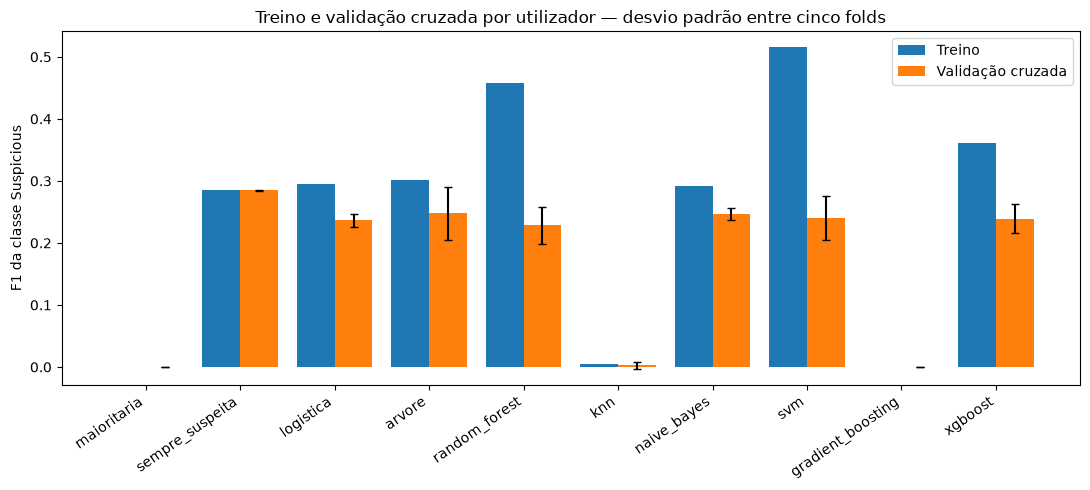

In [2]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(tabela))
ax.bar(x - 0.2, tabela["F1 treino"], 0.4, label="Treino")
ax.bar(x + 0.2, tabela["F1 CV"], 0.4, yerr=tabela["Desvio F1 CV"], capsize=3, label="Validação cruzada")
ax.set_xticks(x, tabela.index, rotation=35, ha="right")
ax.set_ylabel("F1 da classe Suspicious")
ax.set_title("Treino e validação cruzada por utilizador — desvio padrão entre cinco folds")
ax.legend()
fig.tight_layout()
fig.savefig(RAIZ / "resultados/comparacao_modelos.png", dpi=150)
plt.show()

## Protocolo de otimização fixado antes da pesquisa
Serão otimizados os dois classificadores com maior F1 médio na validação cruzada inicial (árvore e Naïve Bayes), acrescentando regressão logística como alternativa simples e regularizada. A pesquisa utilizará apenas os cinco folds de treino, com Pipeline completa.
O limiar será pesquisado conjuntamente com os hiperparâmetros numa grelha limitada de 0, 0,2 e 0,5, dentro da validação cruzada. Incluir zero permite reconhecer explicitamente soluções que equivalem a sinalizar tudo. A validação separada não escolherá o limiar.
A seleção seguirá F1 médio, com Average Precision como critério secundário. Para concretizar a preferência por simplicidade, será usada a heuràstica de **um erro padrão**: entre soluções com F1 pelo menos igual — melhor média menos o seu desvio padrão dividido por raiz de cinco, escolher a mais simples (referência, logística, árvore, Naïve Bayes). Trata-se de uma heuràstica de seleção, não de um intervalo de confiança ou teste de significância: os folds não são amostras independentes.
As referências simples também são candidatas. Se a solução simples permanecer competitiva, não será promovido artificialmente um classificador mais complexo. Os parâmetros, limiar e decisão serão guardados e enviados ao GitHub antes da avaliação no teste.
A comparação de muitas configurações pode introduzir otimismo na validação cruzada; a validação separada e o teste permitirão descrevê-lo, sem reescolher o modelo após ver o teste.